In [36]:
using Plots                          # Plotting
using CSV, DataFrames, JLD2          # Data handling
using LinearAlgebra, StatsBase       # Linear algebra, statistics
using Random, Statistics             # Random number generation, basic statistics
using LaTeXStrings                   # LaTeX support for plots
using Revise                          # Live code reloading

using StaticArrays, LazySets          # Efficient arrays, set operations
using Interpolations, LinearInterpolations  # Interpolation utilities
using SpatiotemporalGPs               # Gaussian processes
using DifferentialEquations, ForwardDiff # Differential equations, automatic differentiation
using Distributions, StatsPlots, SpecialFunctions, Glob # Wind Transformatoins


In [37]:
# Import modules
include("../../../src/jordan_lake_domain.jl")
# include("../../../src/stgpkf.jl")
include("../../../src/kf.jl")
include("../../../src/ngpkf.jl")
include("../../../src/SyntheticData.jl")
include("../../../src/ergodic.jl")
include("../../../src/variograms.jl")
include("../../../src/SOC_Controller.jl")
include("../../../src/simulator_spatial.jl")
include("../../../src/simulator_ST.jl")
include("../../../src/Convex_bound_avoidance.jl")
include("../../../src/transects.jl")

┌ Warning: Replacing docs for `Main.Variograms.hp_fit :: Tuple{Any}` in module `Main.Variograms`
└ @ Base.Docs docs/Docs.jl:243


Main.Transects

In [38]:
# Plot Settings
plot_font = "Computer Modern"
default(
    fontfamily=plot_font,
    linewidth=2,
    guidefontsize=14,
    tickfontsize=14,
    legendfontsize=10,
    titlefontsize=18
)

findnearest(A,x) = argmin(abs.(A .- x))

# Mission domain
polygon_vertices = hcat(JordanLakeDomain.convex_polygon.vertices, JordanLakeDomain.convex_polygon.vertices[:, 1])  # Close the polygon
x0s = [@SVector[0.75, 0.75] for i=1:1]

# Define simulation time-scale/steps
Δt = 2.5 # seconds
dt_min = Δt/(60) # convert ΔT from seconds to minutes
dt_hrs = Δt/(60*60) # convert ΔT from seconds to hours
T_begin = 9.0; # hours
T_end = 12.0; # hours 
ts_hrs = T_begin:dt_hrs:T_end # hours
ts_min = T_begin*60:dt_min:T_end*60


540.0:0.041666666666666664:720.0

In [39]:
# setup the spatial and temporal kernels
σt = 1.0   # m/s
σs = 1.0   # m/s
lt = 0.75*60.0  # minutes
ls = 0.25   # km

kt = Matern(1/2, σt, lt)
ks = Matern(1/2, σs, ls)

# Create spatial domain
# determine the spatial step size
dx = 0.05 # km

# create the spatial domain
xs = 0:dx:1.6
ys = 0:dx:1.9
grid_pts = vec([@SVector[x, y] for x in xs, y in ys]);

In [40]:
# Short Spatial Scale - Long Temporal Scale (SSLT)
file_path = "20250506_stationary_lt45_ls25_sigt1_sigs1.jld2"
f = jldopen(file_path, "r")
sslt_res_ergo_hp = f["res_ergo_hp"]
sslt_synthetic_data = f["synthetic_data"]
sslt_soc_target = f["soc_target"]
sslt_ts_hrs = f["ts_hrs"]
sslt_w_rated_val = f["w_rated_val"]
close(f)

# Long Spatial Scale - Long Temporal Scale (LSLT)
file_path = "20250506_stationary_lt45_ls75_sigt1_sigs1.jld2"
f = jldopen(file_path, "r")
lslt_res_ergo_hp = f["res_ergo_hp"]
lslt_synthetic_data = f["synthetic_data"]
lslt_soc_target = f["soc_target"]
lslt_ts_hrs = f["ts_hrs"]
lslt_w_rated_val = f["w_rated_val"]
close(f)

# Short Spatial Scale - Short Temporal Scale (SSST)
file_path = "20250506_stationary_lt15_ls25_sigt1_sigs1.jld2"
f = jldopen(file_path, "r")
ssst_res_ergo_hp = f["res_ergo_hp"]
ssst_synthetic_data = f["synthetic_data"]
ssst_soc_target = f["soc_target"]
ssst_ts_hrs = f["ts_hrs"]
ssst_w_rated_val = f["w_rated_val"]
close(f)

# Long Spatial Scale - Short Temporal Scale (LSST)
file_path = "20250506_stationary_lt15_ls75_sigt1_sigs1.jld2"
f = jldopen(file_path, "r")
lsst_res_ergo_hp = f["res_ergo_hp"]
lsst_synthetic_data = f["synthetic_data"]
lsst_soc_target = f["soc_target"]
lsst_ts_hrs = f["ts_hrs"]
lsst_w_rated_val = f["w_rated_val"]
close(f)

In [41]:
fields = fieldnames(typeof(ssst_res_ergo_hp))
println(fields)

(:ts, :xs, :us, :speeds, :bs, :measurements, :w_hat_ts, :w_hats, :ergo_q_maps, :q_target_maps)


In [42]:
println("target clarity length: ", length(ssst_res_ergo_hp.q_target_maps))
println("time length: ", length(ssst_res_ergo_hp.ts))
println("q map length: ", length(ssst_res_ergo_hp.ergo_q_maps))

target clarity length: 4321
time length: 4321
q map length: 1441


┌ Info: Saved animation to /home/kmgovind/research/adaptive-ocean-exploration-sim/notebooks/stationary_results/lsst_summary.gif
└ @ Plots /home/kmgovind/.julia/packages/Plots/Ec1L1/src/animation.jl:156


Plots.AnimatedGif("/home/kmgovind/research/adaptive-ocean-exploration-sim/notebooks/stationary_results/lsst_summary.gif")
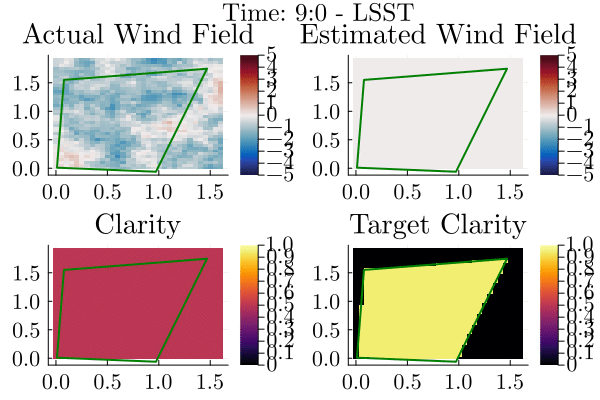

In [43]:
update_idxs = [t in lsst_res_ergo_hp.w_hat_ts ? 1 : 0 for t in lsst_res_ergo_hp.ts]
w_hat_idx = 1
measurement_val = []
estim_val = []
estim_dt = 10 # minutes



estim_vs_real_path = @animate for n = 1:10:length(lsst_res_ergo_hp.ts)-1
    plot()
    heatmap1 = heatmap(lsst_synthetic_data.xs, lsst_synthetic_data.ys, lsst_synthetic_data.data[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        idx = max(lsst_res_ergo_hp.ts[1], lsst_res_ergo_hp.ts[n] - estim_dt)
        new_idx = findnearest(lsst_res_ergo_hp.ts, idx)
        x = [r[i][1] for r in lsst_res_ergo_hp.xs[new_idx:n]]
        y = [r[i][2] for r in lsst_res_ergo_hp.xs[new_idx:n]]
        plot!(x, y, linewidth=3, color=:black, label=false)
    end
    plot!(clims=(-5.0,5.0))
    title!("Actual Wind Field")
    heatmap1 = plot!()
    if lsst_res_ergo_hp.ts[n] in lsst_res_ergo_hp.w_hat_ts
        global w_hat_idx = findfirst(isequal(lsst_res_ergo_hp.ts[n]), lsst_res_ergo_hp.w_hat_ts)
    end
    heatmap2 = heatmap(lsst_synthetic_data.xs, lsst_synthetic_data.ys, lsst_res_ergo_hp.w_hats[w_hat_idx]', cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(-5.0,5.0))
    title!("Estimated Wind Field")
    heatmap2 = plot!()

    # Clarity Plot
    claritymap = heatmap(lsst_synthetic_data.xs, lsst_synthetic_data.ys, lsst_res_ergo_hp.ergo_q_maps[w_hat_idx]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Clarity")
    claritymap = plot!()

    # Error Plot
    targetmap = heatmap(lsst_synthetic_data.xs, lsst_synthetic_data.ys, lsst_res_ergo_hp.q_target_maps[n]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Target Clarity")
    targetmap = plot!()

    p = plot(heatmap1, heatmap2, claritymap, targetmap, layout=(2,2), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60))) - LSST")
    # p = plot(heatmap1, heatmap2, claritymap, layout=(1,3), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")


end
gif(estim_vs_real_path, "stationary_results/lsst_summary.gif")

┌ Info: Saved animation to /home/kmgovind/research/adaptive-ocean-exploration-sim/notebooks/stationary_results/sslt_summary.gif
└ @ Plots /home/kmgovind/.julia/packages/Plots/Ec1L1/src/animation.jl:156


Plots.AnimatedGif("/home/kmgovind/research/adaptive-ocean-exploration-sim/notebooks/stationary_results/sslt_summary.gif")
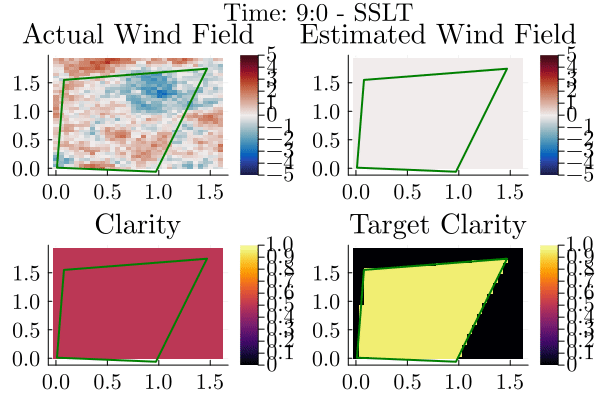

In [44]:
update_idxs = [t in sslt_res_ergo_hp.w_hat_ts ? 1 : 0 for t in sslt_res_ergo_hp.ts]
w_hat_idx = 1
measurement_val = []
estim_val = []
estim_dt = 10 # minutes



estim_vs_real_path = @animate for n = 1:10:length(sslt_res_ergo_hp.ts)-1
    plot()
    heatmap1 = heatmap(sslt_synthetic_data.xs, sslt_synthetic_data.ys, sslt_synthetic_data.data[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        idx = max(sslt_res_ergo_hp.ts[1], sslt_res_ergo_hp.ts[n] - estim_dt)
        new_idx = findnearest(sslt_res_ergo_hp.ts, idx)
        x = [r[i][1] for r in sslt_res_ergo_hp.xs[new_idx:n]]
        y = [r[i][2] for r in sslt_res_ergo_hp.xs[new_idx:n]]
        plot!(x, y, linewidth=3, color=:black, label=false)
    end
    plot!(clims=(-5.0,5.0))
    title!("Actual Wind Field")
    heatmap1 = plot!()
    if sslt_res_ergo_hp.ts[n] in sslt_res_ergo_hp.w_hat_ts
        global w_hat_idx = findfirst(isequal(sslt_res_ergo_hp.ts[n]), sslt_res_ergo_hp.w_hat_ts)
    end
    heatmap2 = heatmap(sslt_synthetic_data.xs, sslt_synthetic_data.ys, sslt_res_ergo_hp.w_hats[w_hat_idx]', cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(-5.0,5.0))
    title!("Estimated Wind Field")
    heatmap2 = plot!()

    # Clarity Plot
    claritymap = heatmap(sslt_synthetic_data.xs, sslt_synthetic_data.ys, sslt_res_ergo_hp.ergo_q_maps[w_hat_idx]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Clarity")
    claritymap = plot!()

    # Error Plot
    targetmap = heatmap(sslt_synthetic_data.xs, sslt_synthetic_data.ys, sslt_res_ergo_hp.q_target_maps[n]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Target Clarity")
    targetmap = plot!()

    p = plot(heatmap1, heatmap2, claritymap, targetmap, layout=(2,2), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60))) - SSLT")
    # p = plot(heatmap1, heatmap2, claritymap, layout=(1,3), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")


end
gif(estim_vs_real_path, "stationary_results/sslt_summary.gif")

┌ Info: Saved animation to /home/kmgovind/research/adaptive-ocean-exploration-sim/notebooks/stationary_results/lslt_summary.gif
└ @ Plots /home/kmgovind/.julia/packages/Plots/Ec1L1/src/animation.jl:156


Plots.AnimatedGif("/home/kmgovind/research/adaptive-ocean-exploration-sim/notebooks/stationary_results/lslt_summary.gif")
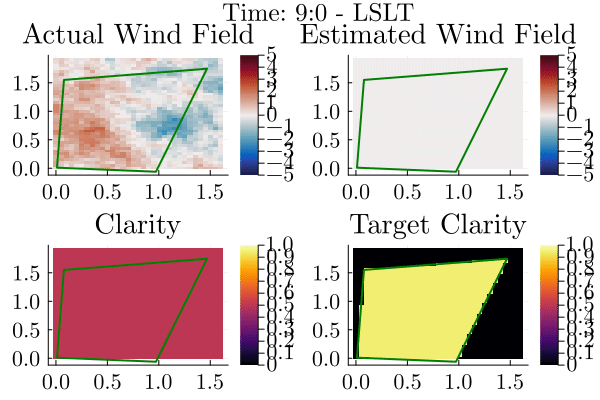

In [45]:
update_idxs = [t in lslt_res_ergo_hp.w_hat_ts ? 1 : 0 for t in lslt_res_ergo_hp.ts]
w_hat_idx = 1
measurement_val = []
estim_val = []
estim_dt = 10 # minutes



estim_vs_real_path = @animate for n = 1:10:length(lslt_res_ergo_hp.ts)-1
    plot()
    heatmap1 = heatmap(lslt_synthetic_data.xs, lslt_synthetic_data.ys, lslt_synthetic_data.data[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        idx = max(lslt_res_ergo_hp.ts[1], lslt_res_ergo_hp.ts[n] - estim_dt)
        new_idx = findnearest(lslt_res_ergo_hp.ts, idx)
        x = [r[i][1] for r in lslt_res_ergo_hp.xs[new_idx:n]]
        y = [r[i][2] for r in lslt_res_ergo_hp.xs[new_idx:n]]
        plot!(x, y, linewidth=3, color=:black, label=false)
    end
    plot!(clims=(-5.0,5.0))
    title!("Actual Wind Field")
    heatmap1 = plot!()
    if lslt_res_ergo_hp.ts[n] in lslt_res_ergo_hp.w_hat_ts
        global w_hat_idx = findfirst(isequal(lslt_res_ergo_hp.ts[n]), lslt_res_ergo_hp.w_hat_ts)
    end
    heatmap2 = heatmap(lslt_synthetic_data.xs, lslt_synthetic_data.ys, lslt_res_ergo_hp.w_hats[w_hat_idx]', cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(-5.0,5.0))
    title!("Estimated Wind Field")
    heatmap2 = plot!()

    # Clarity Plot
    claritymap = heatmap(lslt_synthetic_data.xs, lslt_synthetic_data.ys, lslt_res_ergo_hp.ergo_q_maps[w_hat_idx]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Clarity")
    claritymap = plot!()

    # Error Plot
    targetmap = heatmap(lslt_synthetic_data.xs, lslt_synthetic_data.ys, lslt_res_ergo_hp.q_target_maps[n]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Target Clarity")
    targetmap = plot!()

    p = plot(heatmap1, heatmap2, claritymap, targetmap, layout=(2,2), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60))) - LSLT")
    # p = plot(heatmap1, heatmap2, claritymap, layout=(1,3), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")


end
gif(estim_vs_real_path, "stationary_results/lslt_summary.gif")

┌ Info: Saved animation to /home/kmgovind/research/adaptive-ocean-exploration-sim/notebooks/stationary_results/ssst_summary.gif
└ @ Plots /home/kmgovind/.julia/packages/Plots/Ec1L1/src/animation.jl:156


Plots.AnimatedGif("/home/kmgovind/research/adaptive-ocean-exploration-sim/notebooks/stationary_results/ssst_summary.gif")
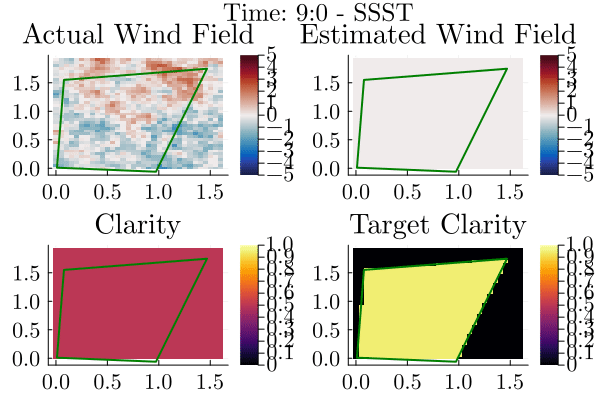

In [46]:
update_idxs = [t in ssst_res_ergo_hp.w_hat_ts ? 1 : 0 for t in ssst_res_ergo_hp.ts]
w_hat_idx = 1
measurement_val = []
estim_val = []
estim_dt = 10 # minutes



estim_vs_real_path = @animate for n = 1:10:length(ssst_res_ergo_hp.ts)-1
    plot()
    heatmap1 = heatmap(ssst_synthetic_data.xs, ssst_synthetic_data.ys, ssst_synthetic_data.data[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        idx = max(ssst_res_ergo_hp.ts[1], ssst_res_ergo_hp.ts[n] - estim_dt)
        new_idx = findnearest(ssst_res_ergo_hp.ts, idx)
        x = [r[i][1] for r in ssst_res_ergo_hp.xs[new_idx:n]]
        y = [r[i][2] for r in ssst_res_ergo_hp.xs[new_idx:n]]
        plot!(x, y, linewidth=3, color=:black, label=false)
    end
    plot!(clims=(-5.0,5.0))
    title!("Actual Wind Field")
    heatmap1 = plot!()
    if ssst_res_ergo_hp.ts[n] in ssst_res_ergo_hp.w_hat_ts
        global w_hat_idx = findfirst(isequal(ssst_res_ergo_hp.ts[n]), ssst_res_ergo_hp.w_hat_ts)
    end
    heatmap2 = heatmap(ssst_synthetic_data.xs, ssst_synthetic_data.ys, ssst_res_ergo_hp.w_hats[w_hat_idx]', cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(-5.0,5.0))
    title!("Estimated Wind Field")
    heatmap2 = plot!()

    # Clarity Plot
    claritymap = heatmap(ssst_synthetic_data.xs, ssst_synthetic_data.ys, ssst_res_ergo_hp.ergo_q_maps[w_hat_idx]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Clarity")
    claritymap = plot!()

    # Error Plot
    targetmap = heatmap(ssst_synthetic_data.xs, ssst_synthetic_data.ys, ssst_res_ergo_hp.q_target_maps[n]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Target Clarity")
    targetmap = plot!()

    p = plot(heatmap1, heatmap2, claritymap, targetmap, layout=(2,2), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60))) - SSST")
    # p = plot(heatmap1, heatmap2, claritymap, layout=(1,3), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")


end
gif(estim_vs_real_path, "stationary_results/ssst_summary.gif")

## Information Plots

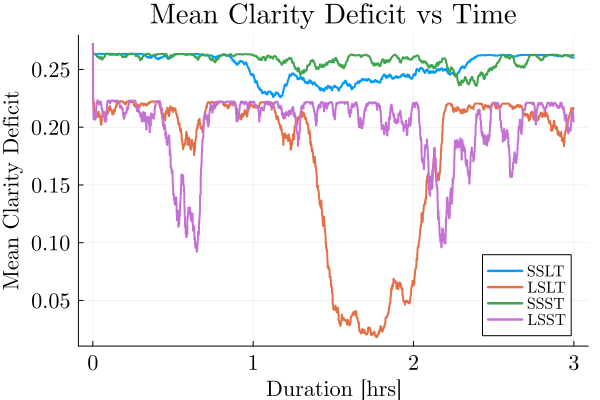

In [47]:
# Compute clarity deficit for each dataset
sslt_clarity_deficit = similar(sslt_res_ergo_hp.q_target_maps');
for n = 1:length(sslt_res_ergo_hp.ts)-1
    w_hat_idx = findnearest(sslt_res_ergo_hp.w_hat_ts, sslt_res_ergo_hp.ts[n])
    sslt_clarity_deficit[n] = max.(0, sslt_res_ergo_hp.q_target_maps[n]' .- sslt_res_ergo_hp.ergo_q_maps[w_hat_idx]')
end
sslt_mean_deficit = [mean(sslt_clarity_deficit[n]) for n in 1:length(sslt_clarity_deficit)-1]


lslt_clarity_deficit = similar(lslt_res_ergo_hp.q_target_maps');
for n = 1:length(lslt_res_ergo_hp.ts)-1
    w_hat_idx = findnearest(lslt_res_ergo_hp.w_hat_ts, lslt_res_ergo_hp.ts[n])
    lslt_clarity_deficit[n] = max.(0, lslt_res_ergo_hp.q_target_maps[n]' .- lslt_res_ergo_hp.ergo_q_maps[w_hat_idx]')
end
lslt_mean_deficit = [mean(lslt_clarity_deficit[n]) for n in 1:length(lslt_clarity_deficit)-1]

ssst_clarity_deficit = similar(ssst_res_ergo_hp.q_target_maps');
for n = 1:length(ssst_res_ergo_hp.ts)-1
    w_hat_idx = findnearest(ssst_res_ergo_hp.w_hat_ts, ssst_res_ergo_hp.ts[n])
    ssst_clarity_deficit[n] = max.(0, ssst_res_ergo_hp.q_target_maps[n]' .- ssst_res_ergo_hp.ergo_q_maps[w_hat_idx]')
end
ssst_mean_deficit = [mean(ssst_clarity_deficit[n]) for n in 1:length(ssst_clarity_deficit)-1]

lsst_clarity_deficit = similar(lsst_res_ergo_hp.q_target_maps');
for n = 1:length(lsst_res_ergo_hp.ts)-1
    w_hat_idx = findnearest(lsst_res_ergo_hp.w_hat_ts, lsst_res_ergo_hp.ts[n])
    lsst_clarity_deficit[n] = max.(0, lsst_res_ergo_hp.q_target_maps[n]' .- lsst_res_ergo_hp.ergo_q_maps[w_hat_idx]')
end
lsst_mean_deficit = [mean(lsst_clarity_deficit[n]) for n in 1:length(lsst_clarity_deficit)-1]




durations = lslt_ts_hrs .- lslt_ts_hrs[1];
plot(durations[1:end-1], sslt_mean_deficit, label="SSLT", color=1, linewidth=2)
plot!(durations[1:end-1], lslt_mean_deficit, label="LSLT", color=2, linewidth=2)
plot!(durations[1:end-1], ssst_mean_deficit, label="SSST", color=3, linewidth=2)
plot!(durations[1:end-1], lsst_mean_deficit, label="LSST", color=4, linewidth=2)

xlabel!("Duration [hrs]")
ylabel!("Mean Clarity Deficit")
title!("Mean Clarity Deficit vs Time")
# plot!(dpi=900)

savefig("stationary_results/mean_clarity_deficit.png")
plot!()


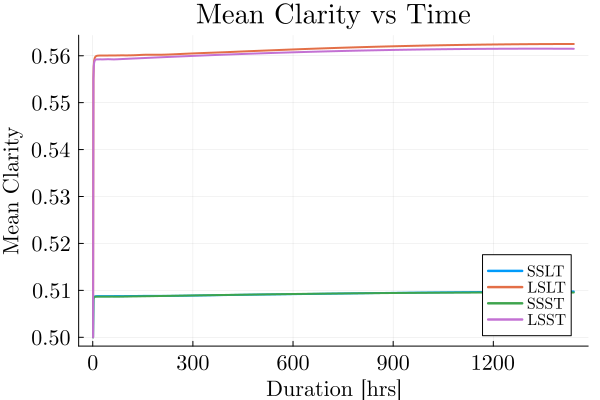

In [48]:
sslt_mean_clarity = [mean(sslt_res_ergo_hp.ergo_q_maps[n]) for n in 1:length(sslt_res_ergo_hp.ergo_q_maps)]
sslt_mean_target_clarity = [mean(sslt_res_ergo_hp.q_target_maps[n]) for n in 1:length(sslt_res_ergo_hp.q_target_maps)]
lslt_mean_clarity = [mean(lslt_res_ergo_hp.ergo_q_maps[n]) for n in 1:length(lslt_res_ergo_hp.ergo_q_maps)]
lslt_mean_target_clarity = [mean(lslt_res_ergo_hp.q_target_maps[n]) for n in 1:length(lslt_res_ergo_hp.q_target_maps)]
ssst_mean_clarity = [mean(ssst_res_ergo_hp.ergo_q_maps[n]) for n in 1:length(ssst_res_ergo_hp.ergo_q_maps)]
ssst_mean_target_clarity = [mean(ssst_res_ergo_hp.q_target_maps[n]) for n in 1:length(ssst_res_ergo_hp.q_target_maps)]
lsst_mean_clarity = [mean(lsst_res_ergo_hp.ergo_q_maps[n]) for n in 1:length(lsst_res_ergo_hp.ergo_q_maps)]
lsst_mean_target_clarity = [mean(lsst_res_ergo_hp.q_target_maps[n]) for n in 1:length(lsst_res_ergo_hp.q_target_maps)]

plot(sslt_mean_clarity, label="SSLT", color=1, linewidth=2)
plot!(lslt_mean_clarity, label="LSLT", color=2, linewidth=2)
plot!(ssst_mean_clarity, label="SSST", color=3, linewidth=2)
plot!(lsst_mean_clarity, label="LSST", color=4, linewidth=2)

xlabel!("Duration [hrs]")
ylabel!("Mean Clarity")
title!("Mean Clarity vs Time")

savefig("stationary_results/mean_clarity.png")
plot!()


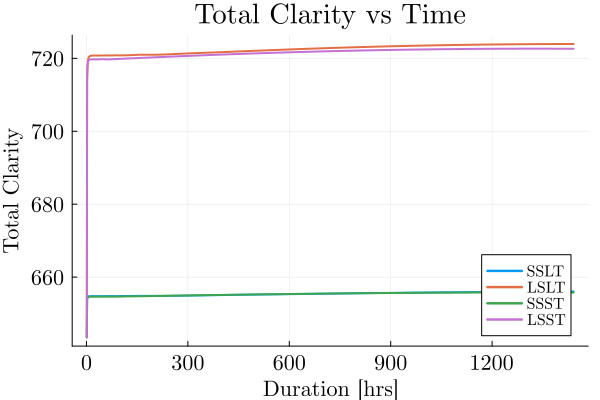

In [49]:
# Calculate total clarity for each time step
sslt_total_clarity = [sum(sslt_res_ergo_hp.ergo_q_maps[n]) for n in 1:length(sslt_res_ergo_hp.ergo_q_maps)]
lslt_total_clarity = [sum(lslt_res_ergo_hp.ergo_q_maps[n]) for n in 1:length(lslt_res_ergo_hp.ergo_q_maps)]
ssst_total_clarity = [sum(ssst_res_ergo_hp.ergo_q_maps[n]) for n in 1:length(ssst_res_ergo_hp.ergo_q_maps)]
lsst_total_clarity = [sum(lsst_res_ergo_hp.ergo_q_maps[n]) for n in 1:length(lsst_res_ergo_hp.ergo_q_maps)]

# Plot total clarity vs time
plot(sslt_total_clarity, label="SSLT", color=1, linewidth=2)
plot!(lslt_total_clarity, label="LSLT", color=2, linewidth=2)
plot!(ssst_total_clarity, label="SSST", color=3, linewidth=2)
plot!(lsst_total_clarity, label="LSST", color=4, linewidth=2)

xlabel!("Duration [hrs]")
ylabel!("Total Clarity")
title!("Total Clarity vs Time")

savefig("stationary_results/total_clarity.png")
plot!()

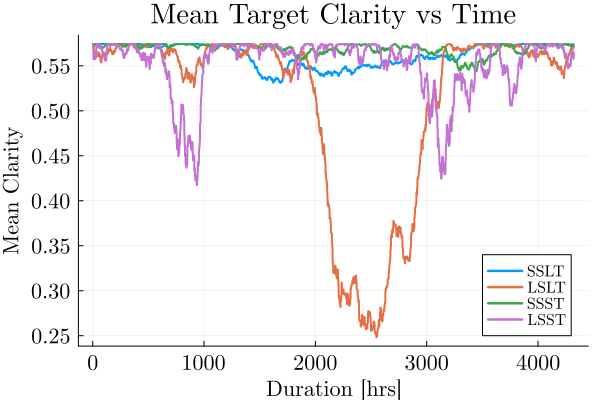

In [50]:
plot(sslt_mean_target_clarity, label="SSLT", color=1, linewidth=2)
plot!(lslt_mean_target_clarity, label="LSLT", color=2, linewidth=2)
plot!(ssst_mean_target_clarity, label="SSST", color=3, linewidth=2)
plot!(lsst_mean_target_clarity, label="LSST", color=4, linewidth=2)
xlabel!("Duration [hrs]")
ylabel!("Mean Clarity")
title!("Mean Target Clarity vs Time")

savefig("stationary_results/mean_target_clarity.png")
plot!()


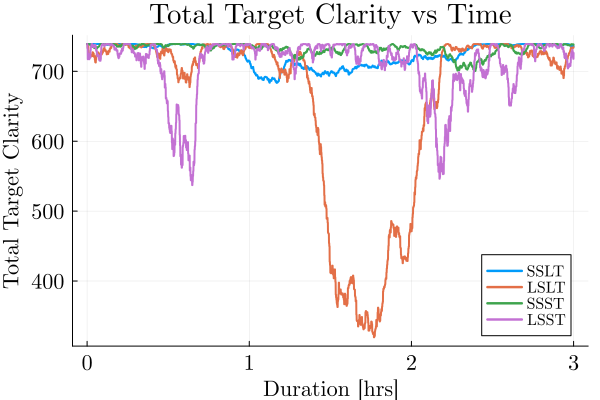

In [51]:
# Calculate total target clarity for each time step
sslt_total_target_clarity = [sum(sslt_res_ergo_hp.q_target_maps[n]) for n in 1:length(sslt_res_ergo_hp.q_target_maps)]
lslt_total_target_clarity = [sum(lslt_res_ergo_hp.q_target_maps[n]) for n in 1:length(lslt_res_ergo_hp.q_target_maps)]
ssst_total_target_clarity = [sum(ssst_res_ergo_hp.q_target_maps[n]) for n in 1:length(ssst_res_ergo_hp.q_target_maps)]
lsst_total_target_clarity = [sum(lsst_res_ergo_hp.q_target_maps[n]) for n in 1:length(lsst_res_ergo_hp.q_target_maps)]


plot(durations, sslt_total_target_clarity, label="SSLT", color=1, linewidth=2)
plot!(durations, lslt_total_target_clarity, label="LSLT", color=2, linewidth=2)
plot!(durations, ssst_total_target_clarity, label="SSST", color=3, linewidth=2)
plot!(durations, lsst_total_target_clarity, label="LSST", color=4, linewidth=2)


xlabel!("Duration [hrs]")
ylabel!("Total Target Clarity")
title!("Total Target Clarity vs Time")

savefig("stationary_results/total_target_clarity.png")
plot!()


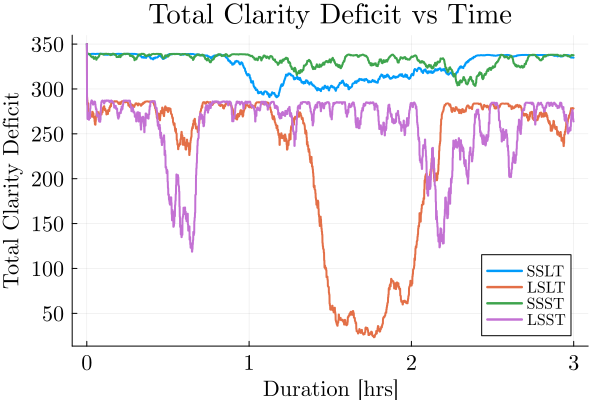

In [52]:
# Calculate total clarity deficit for each time step
sslt_total_clarity_deficit = [sum(sslt_clarity_deficit[n]) for n in 1:length(sslt_clarity_deficit)-1]
lslt_total_clarity_deficit = [sum(lslt_clarity_deficit[n]) for n in 1:length(lslt_clarity_deficit)-1]
ssst_total_clarity_deficit = [sum(ssst_clarity_deficit[n]) for n in 1:length(ssst_clarity_deficit)-1]
lsst_total_clarity_deficit = [sum(lsst_clarity_deficit[n]) for n in 1:length(lsst_clarity_deficit)-1]

plot(durations[1:end-1], sslt_total_clarity_deficit, label="SSLT", color=1, linewidth=2)
plot!(durations[1:end-1], lslt_total_clarity_deficit, label="LSLT", color=2, linewidth=2)
plot!(durations[1:end-1], ssst_total_clarity_deficit, label="SSST", color=3, linewidth=2)
plot!(durations[1:end-1], lsst_total_clarity_deficit, label="LSST", color=4, linewidth=2)

xlabel!("Duration [hrs]")
ylabel!("Total Clarity Deficit")
title!("Total Clarity Deficit vs Time")

savefig("stationary_results/total_clarity_deficit.png")
plot!()
